In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from config import PROCESSED
from utils import load_bg, load_stations, group_summary

pd.set_option("display.float_format", "{:,.2f}".format)

Station records come from the Alternative Fuel Stations API (public, operating stations). Block group data combine ACS 2023 five-year estimates with OPA property records. See `scripts/01_collect_data.py`.

In [2]:
st = load_stations()
bg = load_bg(universe_only=False)
print(f"Stations within 2 mi: {len(st)} | in city: {st.in_city.sum()} | within 1 mi: {st.in_main_buffer.sum()}")
print(f"Block groups: {len(bg)} | analysis universe: {bg.in_universe.sum()}")

Stations within 2 mi: 260 | in city: 182 | within 1 mi: 222
Block groups: 1338 | analysis universe: 1246


## Stations by charger type

In [3]:
main = st[st.in_main_buffer]
pd.DataFrame({
    "stations": [main.has_l2.sum(), main.has_dcfc.sum()],
    "ports": [main.ev_level2_evse_num.sum(), main.ev_dc_fast_num.sum()],
    "open_date missing": [main[main.has_l2].open_date.isna().sum(), main[main.has_dcfc].open_date.isna().sum()],
}, index=["Level 2", "DC fast"])

,stations,ports,open_date missing
Level 2,195,464,0
DC fast,28,171,0


In [4]:
main.assign(open_date=main.open_date.dt.strftime("%Y-%m-%d")).explore(column="has_dcfc", tiles="OpenStreetMap", cmap=["#2b8cbe", "#e34a33"],
             tooltip=["station_name", "ev_network", "ev_level2_evse_num", "ev_dc_fast_num", "open_date"],
             marker_kwds={"radius": 4}, legend_kwds={"caption": "Has DC fast"})

## Block group variables

In [5]:
u = bg[bg.in_universe]
u[["med_income", "garage_share", "attached_share", "zero_veh_share"]].describe()

,med_income,garage_share,attached_share,zero_veh_share
count,"1,229.00","1,246.00","1,246.00","1,246.00"
mean,"63,829.26",0.33,0.60,0.28
std,"30,436.59",0.33,0.28,0.20
min,"13,721.00",0.00,0.00,0.00
25%,"41,296.00",0.03,0.40,0.11
50%,"57,571.00",0.17,0.66,0.24
75%,"82,258.00",0.64,0.84,0.42
max,"192,727.00",1.00,1.00,1.00


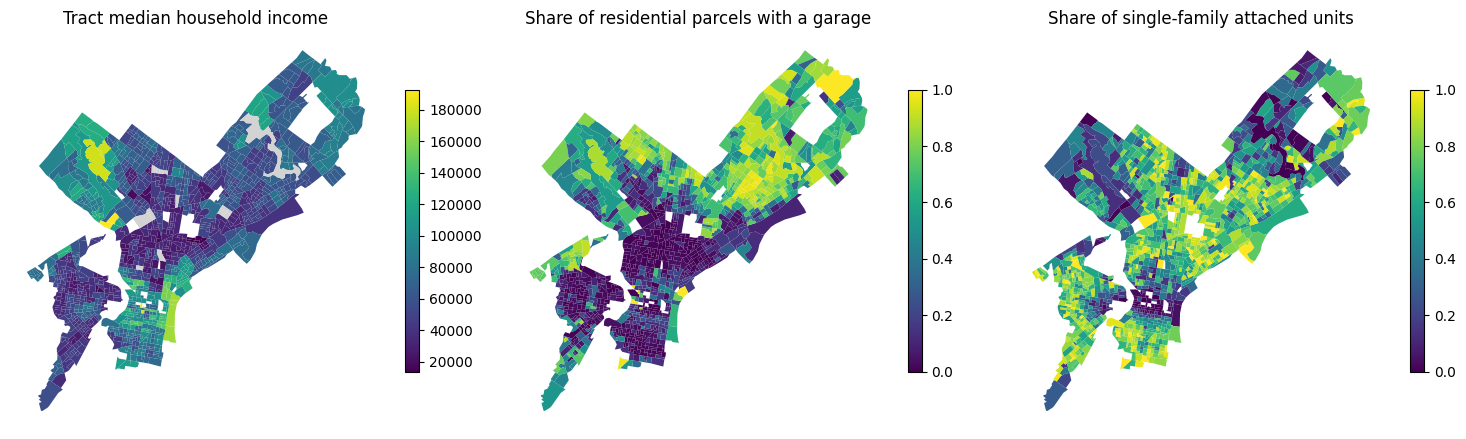

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, title in zip(axes, ["med_income", "garage_share", "attached_share"],
                          ["Tract median household income", "Share of residential parcels with a garage", "Share of single-family attached units"]):
    u.plot(column=col, cmap="viridis", legend=True, ax=ax, missing_kwds={"color": "lightgrey"},
           legend_kwds={"shrink": 0.6})
    ax.set_title(title); ax.set_axis_off()
plt.tight_layout()